# Musky habitat matrix: components x lake-floor elevations

Evaluates every scenario in `michiganhuron_avg.csv` for lake-floor elevations **573-579 ft IGLD85** (1 ft steps) and draws a 3 x 7 matrix of raw (non-interpolated) response surfaces: rows are habitat components, columns are floor elevations. The calculation is identical to `musky_573.ipynb` ... `musky_579.ipynb`.

| Component | Monthly conditions | Qualifying unit |
| --- | --- | --- |
| Juvenile habitat | Depth **> 0.3 m** (strict), May-August | All 4 months pass -> qualifying year |
| Spawning zones | Depth **0.3-1.5 m** (inclusive), May-June | Both months pass -> qualifying year |
| Recruitment zones | Depth **0.3-0.6 m** (inclusive), May-June | Both months pass -> *recruitment year*; a **rolling 5-year window** qualifies when **>= 3** of its 5 years are recruitment years |


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from climate_canvas.plots_utilities import plot_response_surface
from IPython.display import Markdown, display
from matplotlib.colors import Normalize, TwoSlopeNorm

from hydropattern.parsers import duration_parser, magnitude_parser, timing_parser
from hydropattern.patterns import Component
from hydropattern.scenario_grid import build_grid, parse_scenario_name
from hydropattern.scenarios import evaluate_scenarios
from hydropattern.timeseries import Timeseries

## Units, datum, timing

- Lake levels are monthly averages in **meters, IGLD85**; lake-floor elevations are **feet, IGLD85** (same datum). Conversion: **1 ft = 0.3048 m** exactly; floor elevations are rounded to 4 decimals (exact for integer feet).
- Water depth = lake level - floor elevation. Negative values (floor above the lake) are not clipped and fail every criterion.
- Thresholds are expressed as lake-level elevations (floor + depth). A `1e-9 m` tolerance protects the equality boundaries from floating-point artifacts; levels have 0.01 m resolution, so it cannot change a result. The juvenile `> 0.3 m` limit is strict: a level exactly 0.3 m deep fails.
- Calendar years are used (Jan 1 start). Hydropattern uses a leap-normalized 365-day calendar: May 1 = day 121, Jun 1 = 152, Jul 1 = 182, Aug 1 = 213. Monthly timestamps fall on the first of each month, so juvenile habitat evaluates days 121-243 (4 observations) and spawning/recruitment evaluate days 121-181 (2 observations).
- Monthly averages are used directly (no smoothing or daily interpolation). Passing every monthly mean does not prove the threshold held every day; wind setup, seiche, and intra-month variability are not represented.

## Reporting contract

- Only complete Jan-Dec years are scored; partial end years are excluded. Missing or duplicate timestamps are rejected.
- Components also carry a hydropattern duration gate: all **4 consecutive monthly observations** must meet juvenile criteria; both **2 consecutive monthly observations** must meet spawning/recruitment criteria. Duration counts monthly timesteps, not elapsed days. Annual reporting independently checks every required month.
- **Juvenile / spawning surface value** = `100 x qualifying complete years / complete years`.
- **Recruitment surface value** = `100 x rolling 5-year windows with >=3 recruitment years / all full 5-year windows`. Windows overlap and partial windows at the record ends are excluded, so it is a window percentage, not a year percentage.
- An unknown annual verdict (not expected: all levels are finite) would give a range of possible percentages; the plotted value is then the **midpoint** and the `Midpoint used` column is flagged. The notebook prints whether this rule was needed.
- These are depth-only habitat screens; they are not a validated musky population model (temperature, vegetation, ice-out, wave exposure, and substrate are outside this analysis).

In [2]:
# ---- Units and datum -------------------------------------------------------
# Lake levels (m, IGLD85) and lake-floor elevations (ft, IGLD85) share a datum.
FT_TO_M = 0.3048                      # exact international foot
DEPTHS_FT = tuple(range(573, 580))    # lake-floor elevations evaluated (ft IGLD85)
EPS = 1e-9                            # float tolerance only; levels have 0.01 m resolution

# ---- Habitat criteria (depths in m) -----------------------------------------
JUVENILE_MIN_DEPTH_M = 0.3            # strictly deeper than
SPAWNING_DEPTH_M = (0.3, 1.5)         # inclusive
RECRUITMENT_DEPTH_M = (0.3, 0.6)      # inclusive
JUVENILE_MONTHS = (5, 6, 7, 8)        # May-Aug, all four must pass
EARLY_MONTHS = (5, 6)                 # May-Jun, both must pass
# Leap-normalized day-of-year: May 1 = 121, Jun 1 = 152, Jul 1 = 182, Aug 1 = 213.
JUVENILE_DOY = (121, 243)
EARLY_DOY = (121, 181)
WINDOW_YEARS, WINDOW_REQUIRED = 5, 3  # recruitment: >=3 successful years per 5

REQUIRED_MONTHS = {'juvenile_habitat': JUVENILE_MONTHS,
                   'spawning_zones': EARLY_MONTHS,
                   'recruitment_zones': EARLY_MONTHS}
COMPONENT_ORDER = tuple(REQUIRED_MONTHS)
COMPONENT_TITLES = {
    'juvenile_habitat': 'Juvenile habitat: depth > 0.3 m in all of May-Aug',
    'spawning_zones': 'Spawning zones: depth 0.3-1.5 m in both May and Jun',
    'recruitment_zones': 'Recruitment zones: depth 0.3-0.6 m in May and Jun, in >=3 of every 5 years',
}
COMPONENT_UNITS = {
    'juvenile_habitat': 'Complete years meeting condition (%)',
    'spawning_zones': 'Complete years meeting condition (%)',
    'recruitment_zones': 'Rolling 5-yr windows with >=3 recruitment years (%)',
}


def bottom_m(bottom_ft: float) -> float:
    return round(bottom_ft * FT_TO_M, 4)


def level_at_depth(bottom_ft: float, depth_m: float) -> float:
    return round(bottom_m(bottom_ft) + depth_m, 4)


def build_components(bottom_ft: float) -> dict[str, Component]:
    def lvl(depth_m):
        return level_at_depth(bottom_ft, depth_m)

    def component(name, doy, magnitude, duration_months):
        return Component(
            name=name,
            characteristics=[
                timing_parser(list(doy), order=1)._replace(name='season'),
                magnitude_parser(magnitude, order=2)._replace(name='depth'),
                duration_parser(['>=', duration_months], order=3)
                ._replace(name='season_duration'),
            ],
            is_success_pattern=True,
        )

    return {
        'juvenile_habitat': component(
            'juvenile_habitat', JUVENILE_DOY,
            ['>', lvl(JUVENILE_MIN_DEPTH_M) + EPS], len(JUVENILE_MONTHS)),
        'spawning_zones': component(
            'spawning_zones', EARLY_DOY,
            [lvl(SPAWNING_DEPTH_M[0]) - EPS, lvl(SPAWNING_DEPTH_M[1]) + EPS],
            len(EARLY_MONTHS)),
        'recruitment_zones': component(
            'recruitment_zones', EARLY_DOY,
            [lvl(RECRUITMENT_DEPTH_M[0]) - EPS, lvl(RECRUITMENT_DEPTH_M[1]) + EPS],
            len(EARLY_MONTHS)),
    }


def complete_year_labels(dates: pd.DatetimeIndex) -> list[int]:
    if dates.hasnans or not dates.is_unique or not dates.is_monotonic_increasing:
        raise ValueError('Monthly timestamps must be valid, unique, and increasing.')
    if len(dates) < 2 or not (dates.day == 1).all() or not np.all(
            np.diff(dates.year * 12 + dates.month) == 1):
        raise ValueError('Expected consecutive monthly observations on the first of each month.')
    counts = pd.Series(dates.year).value_counts().sort_index()
    return counts.index[counts.eq(12)].tolist()


def annual_verdicts(outcomes: pd.Series, required_months: tuple[int, ...]) -> pd.Series:
    # 1 = every required month passed, 0 = any required month failed, NaN = otherwise unknown
    complete = complete_year_labels(outcomes.index)
    if not complete:
        raise ValueError('No complete January-December years are available.')
    verdicts = {}
    for label, year in outcomes.groupby(outcomes.index.year):
        if label not in complete:
            continue
        required = year.loc[year.index.month.isin(required_months)]
        if len(required) != len(required_months):
            raise ValueError('Required monthly observations are not unique and complete.')
        verdicts[int(label)] = (
            0.0 if required.eq(0).any() else 1.0 if required.eq(1).all() else np.nan)
    return pd.Series(verdicts, name=outcomes.name, dtype=float).rename_axis('Year')


def window_verdicts(annual: pd.Series, window: int = WINDOW_YEARS,
                    required: int = WINDOW_REQUIRED) -> pd.Series:
    # Rolling windows of consecutive complete years; partial windows at the record ends are excluded.
    if len(annual) < window or not np.all(np.diff(annual.index) == 1):
        raise ValueError('Rolling windows need consecutive complete years covering a full window.')
    verdicts = {}
    for start in range(len(annual) - window + 1):
        chunk = annual.iloc[start:start + window]
        successes, unknown = int(chunk.eq(1).sum()), int(chunk.isna().sum())
        verdicts[int(chunk.index[0])] = (
            1.0 if successes >= required else 0.0 if successes + unknown < required else np.nan)
    return pd.Series(verdicts, name=annual.name, dtype=float).rename_axis('Window start year')


def verdict_summary(verdicts: pd.Series) -> dict:
    # Unknown verdicts bound the percentage; the plotted value is the midpoint of the bounds.
    total = len(verdicts)
    if total == 0:
        raise ValueError('Percentages require at least one evaluated year or window.')
    successes, unknown = int(verdicts.eq(1).sum()), int(verdicts.isna().sum())
    lower, upper = 100 * successes / total, 100 * (successes + unknown) / total
    return {'Evaluated units': total, 'Successes': successes,
            'Failures': int(verdicts.eq(0).sum()), 'Unknown': unknown,
            'Lower percentage': lower, 'Upper percentage': upper,
            'Percentage': (lower + upper) / 2, 'Midpoint used': unknown > 0}


def load_levels(csv_path):
    ts = Timeseries.from_csv(str(csv_path), first_dowy=1, date_format='%Y-%m-%d')
    names = list(ts.data.columns[:-1])
    values = ts.data[names].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Missing/infinite lake levels cannot be evaluated.')
    if '_0_0' not in names or any(parse_scenario_name(n) is None for n in names):
        raise ValueError('Expected baseline _0_0 and precipitation/temperature scenario names.')
    if not complete_year_labels(ts.data.index):
        raise ValueError('No complete January-December years.')
    return ts, names


def evaluate_depth(ts: Timeseries, scenario_names: list[str], bottom_ft: float) -> pd.DataFrame:
    components = build_components(bottom_ft)
    evaluated = evaluate_scenarios(ts, list(components.values()))
    rows = []
    for key in COMPONENT_ORDER:
        results = evaluated.by_component(key)
        for name in scenario_names:
            annual = annual_verdicts(results[name].df[key], REQUIRED_MONTHS[key])
            scored = window_verdicts(annual) if key == 'recruitment_zones' else annual
            precipitation, temperature = parse_scenario_name(name)
            rows.append({
                'Bottom (ft)': bottom_ft, 'Component': key, 'Scenario': name,
                'Precipitation delta (%)': precipitation, 'Temperature delta (deg C)': temperature,
                'Complete years': len(annual), 'Successful years': int(annual.eq(1).sum()),
                **verdict_summary(scored),
            })
    return pd.DataFrame(rows).set_index(['Component', 'Scenario'])

In [3]:
example = next(
    root / 'data' / 'avg'
    for root in (Path.cwd(), *Path.cwd().parents)
    if (root / 'data' / 'avg' / 'michiganhuron_avg.csv').is_file()
)
ts, scenario_names = load_levels(example / 'michiganhuron_avg.csv')
dates = ts.data.index
levels = ts.data[scenario_names]
complete_years = complete_year_labels(dates)
print(f'{len(dates):,} monthly averages; {len(complete_years)} complete years '
      f'({complete_years[0]}-{complete_years[-1]}); {len(scenario_names)} scenarios; no missing levels.')
print(f'Lake level range: {levels.to_numpy().min():.2f}-{levels.to_numpy().max():.2f} m IGLD85 '
      f'({levels.to_numpy().min() / FT_TO_M:.2f}-{levels.to_numpy().max() / FT_TO_M:.2f} ft).')

12,360 monthly averages; 1030 complete years (1970-2999); 17 scenarios; no missing levels.
Lake level range: 173.02-178.65 m IGLD85 (567.65-586.12 ft).


## Evaluate every depth

In [4]:
summary_all = {ft: evaluate_depth(ts, scenario_names, float(ft)) for ft in DEPTHS_FT}
combined = pd.concat(summary_all.values())
print('Midpoint rule needed for:', 'none (all verdicts definite)' if not combined['Midpoint used'].any()
      else combined.index[combined['Midpoint used']].tolist())
baseline_table = combined.xs('_0_0', level='Scenario').reset_index().pivot(
    index='Bottom (ft)', columns='Component', values='Percentage')[list(COMPONENT_ORDER)]
display(baseline_table.round(1))

Midpoint rule needed for: none (all verdicts definite)


Component,juvenile_habitat,spawning_zones,recruitment_zones
Bottom (ft),,,
573.0,100.0,7.4,0.0
574.0,100.0,32.3,0.0
575.0,100.0,65.8,0.0
576.0,99.2,91.4,3.6
577.0,87.6,85.8,13.5
578.0,56.6,56.9,15.5
579.0,24.6,24.9,11.7


## Component x depth matrices

The juvenile and spawning components share a 0-100% color scale across 14 panels. Recruitment is shown separately in a seven-panel figure with a 0-20% color scale to make its low percentages distinguishable; values above 20%, if any, saturate at the colorbar maximum. Every panel uses climate-canvas default `RdBu`; baseline is shown as an ordinary scenario cell, without a marker. Numbers show exact plotted percentages. Gray cells indicate missing scenario combinations. Change `PLOT_DEPTHS_FT` to redraw a depth subset; set `ANNOTATE = False` to hide values.

In [5]:
ROW_LABELS = {
    'juvenile_habitat': 'Juvenile habitat\n> 0.3 m, May-Aug\n(% of years)',
    'spawning_zones': 'Spawning zones\n0.3-1.5 m, May-Jun\n(% of years)',
    'recruitment_zones': 'Recruitment zones\n0.3-0.6 m, May-Jun,\n>=3 of 5 yrs\n(% of 5-yr windows)',
}


def _plot_component_matrix(summary_all, depths_ft, component_keys, vmax, annotate,
                           figsize_height, figure_title, colorbar_label, cmap='RdBu'):
    depths_ft = list(depths_ft)
    fig, axes = plt.subplots(len(component_keys), len(depths_ft), sharex=True, sharey=True,
                             figsize=(3.6 * len(depths_ft), figsize_height),
                             squeeze=False, constrained_layout=True)
    norm = Normalize(vmin=0, vmax=vmax)
    mesh = None
    for col, ft in enumerate(depths_ft):
        for row, key in enumerate(component_keys):
            ax = axes[row, col]
            rows = summary_all[ft].loc[key]
            xs, ys, grid = build_grid(list(rows.index), rows['Percentage'].to_dict())
            mesh = ax.pcolormesh(xs, ys, grid, shading='nearest', cmap=cmap, norm=norm)
            ax.set_facecolor('0.85')
            ax.set_xticks(xs)
            ax.set_yticks(ys)
            ax.grid(linestyle='--', color='gray', alpha=0.4)
            if annotate:
                for i, y in enumerate(ys):
                    for j, x in enumerate(xs):
                        if np.isfinite(grid[i, j]):
                            value = grid[i, j]
                            color = ('white' if value < vmax * 0.15 else 'black') if vmax == 20 else (
                                'white' if value > 60 else 'black')
                            ax.text(x, y, f'{value:.0f}', ha='center', va='center',
                                    fontsize=6.5, color=color)
            if row == 0:
                ax.set_title(f'{ft} ft ({bottom_m(ft):.2f} m)', fontsize=11, fontweight='bold')
            if col == 0:
                ax.set_ylabel(ROW_LABELS[key] + '\nTemperature delta (deg C)', fontsize=9)
            if row == len(component_keys) - 1:
                ax.set_xlabel('Precipitation delta (%)', fontsize=9)
            ax.tick_params(labelsize=8)
    cbar = fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.01)
    cbar.set_label(colorbar_label)
    fig.suptitle(figure_title, fontsize=13)
    return fig


def plot_depth_component_matrix(summary_all, depths_ft=DEPTHS_FT, annotate=True, cmap='RdBu'):
    # Juvenile and spawning use a shared full 0-100% scale.
    return _plot_component_matrix(
        summary_all, depths_ft, COMPONENT_ORDER[:2], 100, annotate,
        figsize_height=8.2,
        figure_title=('Musky juvenile and spawning success by lake-floor elevation (IGLD85)\n'
                      'Raw scenario cells (no interpolation); gray = no scenario'),
        colorbar_label='Success (% of complete years)', cmap=cmap)


def plot_recruitment_matrix(summary_all, depths_ft=DEPTHS_FT, annotate=True, cmap='RdBu'):
    # Recruitment percentages are low, so use expanded 0-20% color contrast.
    return _plot_component_matrix(
        summary_all, depths_ft, ('recruitment_zones',), 20, annotate,
        figsize_height=4.8,
        figure_title=('Musky recruitment success by lake-floor elevation (IGLD85)\n'
                      'Percent of rolling 5-year windows with >=3 successful years; raw cells, no interpolation'),
        colorbar_label='Successful rolling 5-year windows (%) | color scale: 0-20%', cmap=cmap)


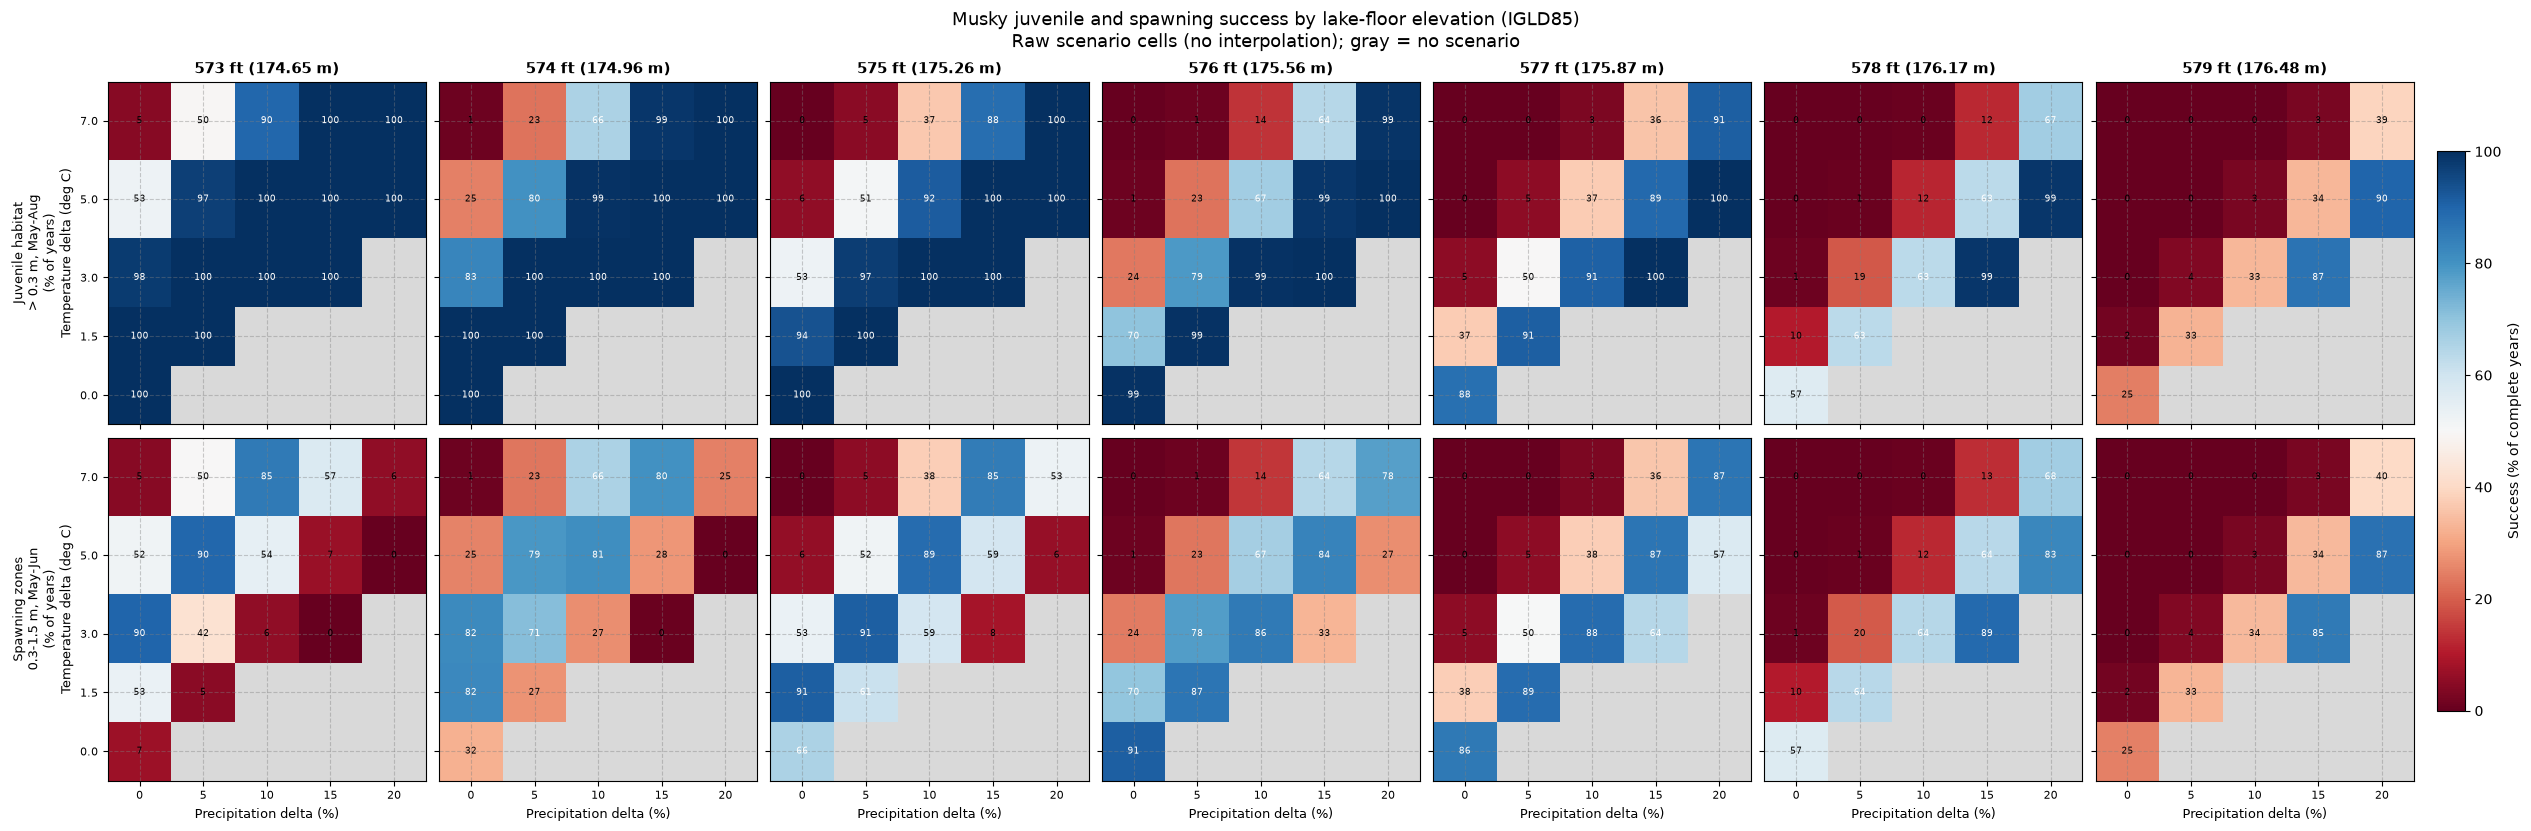

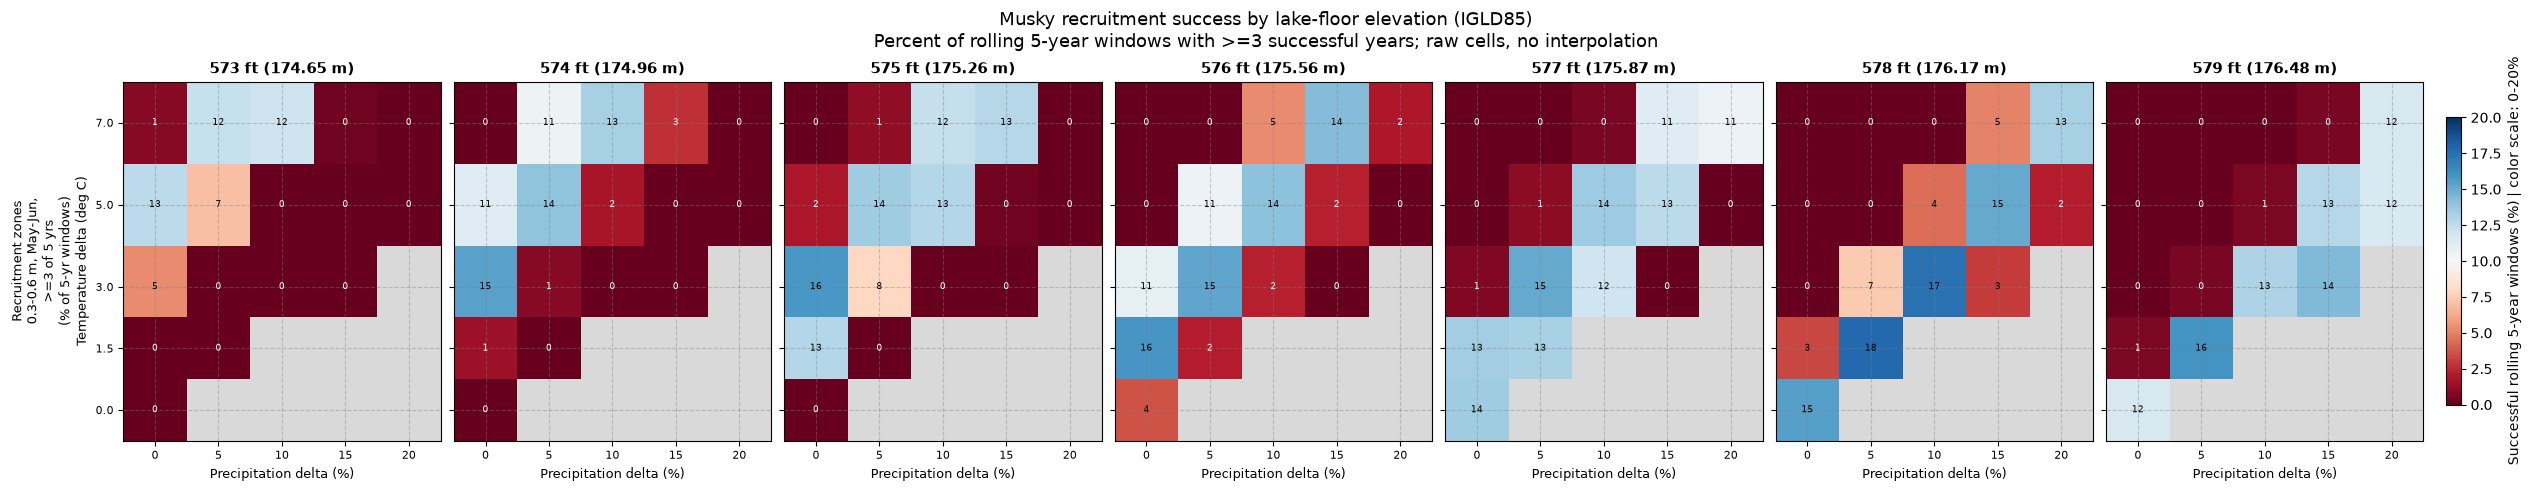

In [6]:
PLOT_DEPTHS_FT = DEPTHS_FT   # e.g. (574, 575, 576)
ANNOTATE = True
fig = plot_depth_component_matrix(summary_all, PLOT_DEPTHS_FT, annotate=ANNOTATE)
plt.show()
plt.close(fig)

recruitment_fig = plot_recruitment_matrix(summary_all, PLOT_DEPTHS_FT, annotate=ANNOTATE)
plt.show()
plt.close(recruitment_fig)


The recruitment row is a percentage of overlapping rolling 5-year windows, while the other rows are percentages of years; all percentages describe this supplied record at fixed floor elevations.